# Drone detection and Kalman-filter tracking

A camera watching the sky for small drones has two jobs. It has to find the drone in a single frame, and it has to follow the same drone from frame to frame when the detector misses it, mistakes a bird or a branch for it, or loses it behind a tree. In this assignment you do both on the DUT Anti-UAV benchmark ([Zhao et al., 2022](https://arxiv.org/abs/2205.10851)). You fine-tune a small single-stage detector on a subset of the benchmark's 5,200 training images, measure its average precision on the 2,200 test images, and then wrap it in a Kalman filter that tracks the drone through the benchmark's 20 videos.

The detector alone is a strong baseline. In each frame you can take its most confident box and call that the track. This assignment asks whether a Kalman filter with a constant-velocity motion model improves on that, by how much, and where it fails. You answer it with the one-pass evaluation used for single-object trackers: a success curve over box overlap thresholds and a precision curve over center-distance thresholds, scored on all 20 sequences.

The [Kalman filter lecture](/aiml-common/lectures/rse/kalman-filters) derives the predict and update equations you implement here.

The parts marked `TODO` are yours. Each one starts as a stub that runs, so the whole assignment runs top to bottom from the start and the scoring code reports a baseline: a detector fine-tuned for 3 epochs, and a tracker that reports the detector's most confident box in every frame. Your fine-tuned detector has to beat the 3-epoch detector. For the tracker, measure how it differs from the detector alone on every score and explain the difference. A filter that ties or loses on some scores is a valid result if you can say why. Finding the drone again after the track is lost is a firm requirement, set out in the section on losing and reacquiring the drone. Everything else, including the data loading and the scoring code, is given so that every submission is scored the same way. Do not change the scoring code.

In [1]:
%pip install -q ultralytics filterpy datasets

In [2]:
import io
import json
import pickle
import random
import shutil
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

## Settings

The defaults train on a random subset of 2,000 of the 5,200 training images and pick the best epoch on 400 validation images, which keeps training short. Keep them for the graded run. You may also raise `TRAIN_LIMIT` and `EPOCHS` and report both runs.

In [3]:
DATA = Path("dut-data")  # everything downloaded or derived goes here
RUNS = Path("runs")  # detector training output
TRAIN_LIMIT = 2000  # training images used; None uses all 5,200
VAL_LIMIT = 400  # validation images used to pick the best epoch
EPOCHS = 30  # fine-tuning epochs
IMGSZ = 640  # training input size in pixels
TRACK_IMGSZ = 640  # detector input size on the tracking frames; you may try 1280
DEVICE = 0 if torch.cuda.is_available() else "cpu"
AMP = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 7  # fp16 needs tensor cores
random.seed(0)
np.random.seed(0)
DATA.mkdir(exist_ok=True)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

Tesla T4


## The detection data

The detection part of DUT Anti-UAV has 10,000 visible-light images split into 5,200 for training, 2,600 for validation and 2,200 for testing. They hold 10,109 labeled drones of a single class, `UAV`. Each image comes with a Pascal VOC annotation, one box per drone given by its corner coordinates `[xmin, ymin, xmax, ymax]` in pixels. Three training images contain no drone.

The drones are small. The median box is about 2% of the image width, so a drone in a 1920 pixel frame is roughly 40 pixels wide and shrinks to about 14 pixels when the frame is resized to the 640 pixel input of the detector. The images range from 240 to 5,616 pixels on the long side, so they are resized once, to at most 1,280 pixels, when they are converted to the detector's label format. The conversion writes one text line per box: the class index followed by the box center, width and height, each divided by the image size.

In [4]:
from datasets import Image as ImageFeature
from datasets import load_dataset

DETECTION = load_dataset("aegean-ai/dut-anti-uav", "detection")
DETECTION = DETECTION.cast_column("image", ImageFeature(decode=False))  # keep raw JPEG bytes
for split, rows in DETECTION.items():
    print(f"{split}: {len(rows)} images, {sum(len(o['bbox']) for o in rows['objects'])} boxes")

README.md:   0%|          | 0.00/6.45k [00:00<?, ?B/s]

detection-parquet/train/train-00000.parq(…): reconstructing file:   0%|          |  0.00B / 92.4MB            

detection-parquet/train/train-00000.parq(…): downloading bytes:           |  0.00B            

detection-parquet/train/train-00001.parq(…): reconstructing file:   0%|          |  0.00B /  177MB            

detection-parquet/train/train-00001.parq(…): downloading bytes:           |  0.00B            

detection-parquet/train/train-00002.parq(…): reconstructing file:   0%|          |  0.00B /  158MB            

... (19 outputs left out)

Generating train split:   0%|          | 0/5200 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2600 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2200 [00:00<?, ? examples/s]

train: 5200 images, 5243 boxes
validation: 2600 images, 2621 boxes
test: 2200 images, 2245 boxes


In [5]:
def rows_to_yolo(rows, out_dir, split, limit=None, max_side=1280, seed=0, exclude=()):
    """Write a YOLO-format copy of one split of the Parquet detection set.

    rows is a datasets split with the image column left undecoded (raw JPEG bytes).
    Images whose image_id is in exclude are skipped before the subset is drawn. Each image is shrunk so its long side is at most max_side; YOLO labels are relative
    to the image size, so they do not change with the resize. Returns the image count.
    """
    out_dir = Path(out_dir)
    excluded = set(exclude)
    indices = [i for i, image_id in enumerate(rows["image_id"]) if image_id not in excluded]
    if limit is not None and limit < len(indices):
        indices = sorted(random.Random(seed).sample(indices, limit))
    img_out = out_dir / "images" / split
    lbl_out = out_dir / "labels" / split
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)
    for row in rows.select(indices):
        width, height = row["width"], row["height"]
        image = Image.open(io.BytesIO(row["image"]["bytes"]))
        scale = max_side / max(image.size)
        if scale < 1:
            target = (round(image.size[0] * scale), round(image.size[1] * scale))
            image.draft("RGB", target)  # fast JPEG decode at reduced size
            image = image.convert("RGB").resize(target, Image.BILINEAR)
        else:
            image = image.convert("RGB")
        image.save(img_out / f"{row['image_id']}.jpg", quality=95)
        lines = []
        for x1, y1, x2, y2 in row["objects"]["bbox"]:  # Pascal VOC corners in pixels
            cx, cy = (x1 + x2) / 2 / width, (y1 + y2) / 2 / height
            w, h = (x2 - x1) / width, (y2 - y1) / height
            lines.append(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
        (lbl_out / f"{row['image_id']}.txt").write_text("\n".join(lines))
    return len(indices)

Some detection images are frames cut from the tracking videos you will score the tracker on. Matching every detection image against every tracking frame finds 517 of them, from 11 of the 20 videos: 285 in the training split, 139 in the validation split and 93 in the test split. A detector trained on those frames has already seen the exact scenes, and often the exact drone positions, that the tracker is later scored on. The training and validation frames are held out below, so the training subset is drawn from the remaining images. The test split stays complete, so its average precision is comparable with published results.

In [6]:
# Detection images that are frames of the 20 tracking videos (found by image matching).
TRACKING_FRAMES_TRAIN = """
    00263 00271 00398 00399 00403 00404 00869 00870 00871 00872 00873 00874 00885 00886
    00887 00888 00889 00890 00891 00892 00893 00894 00895 00896 00897 00898 00899 00900
    00901 00902 00903 00904 00905 00906 00907 00908 00909 00910 00944 00945 00946 00947
    00948 00949 00950 00951 00952 00953 00954 00955 00956 00957 00958 00959 00960 00961
    00962 00963 00964 00965 00966 00967 00968 00969 00970 00971 00972 00973 00974 00975
    00976 00977 00978 00979 00980 00981 00982 00983 00984 00985 00986 00987 00988 01239
    01240 01241 01242 01243 01244 01245 01246 01247 01248 01249 01250 02935 02936 02937
    02938 02939 02940 02941 02942 02943 02944 02945 02946 02947 02948 02949 02950 02951
    02952 02953 02954 02955 02956 02957 02958 02959 02960 02961 02962 02963 02964 02965
    02966 02967 02968 02969 02970 02971 02972 02973 02974 03138 03139 03140 03141 03142
    03143 03144 03145 03146 03147 03148 03149 03150 03151 03152 03153 03154 03155 03156
    03157 03158 03159 03160 03161 03162 03163 03164 03165 03166 03167 03168 03363 03364
    03365 03366 03367 03368 03369 03370 03371 03372 03373 03374 03375 03376 03377 03378
    03379 03380 03381 03382 03383 03384 03385 03386 03387 03844 03845 03846 03847 03848
    03849 03850 03851 03852 03853 03854 03855 03856 03857 03858 03859 03860 03861 03862
    03863 03864 03865 03866 03867 03868 03869 03870 03871 03872 03873 03874 03875 03876
    03877 03878 03879 03880 03881 03882 03883 03884 03917 03918 03919 03920 03921 03922
    03923 03924 03925 03926 03927 03928 03929 03930 03931 03932 03933 03934 03935 03936
    03937 03938 03939 03940 03941 03942 03943 03944 03945 03946 03947 03948 03949 03950
    03951 03952 03953 03954 03955 03956 03957 03958 03959 03960 03961 03962 03963 03964
    03965 03966 03967 03968 03969
""".split()
TRACKING_FRAMES_VAL = """
    00200 00202 00203 00436 00437 00444 00445 00446 00447 00448 00449 00450 00451 00452
    00453 00454 00455 00473 00474 00475 00476 00477 00478 00479 00480 00481 00482 00483
    00484 00485 00486 00487 00488 00489 00490 00491 00492 00493 00494 00495 00621 00622
    00623 00624 00625 01469 01470 01471 01472 01473 01474 01475 01476 01477 01478 01479
    01480 01481 01482 01483 01484 01485 01486 01487 01570 01571 01572 01573 01574 01575
    01576 01577 01578 01579 01580 01581 01582 01583 01584 01585 01683 01684 01685 01686
    01687 01688 01689 01690 01691 01692 01693 01694 01923 01924 01925 01926 01927 01928
    01929 01930 01931 01932 01933 01934 01935 01936 01937 01938 01939 01940 01941 01942
    01959 01960 01961 01962 01963 01964 01965 01966 01967 01968 01969 01970 01971 01972
    01973 01974 01975 01976 01977 01978 01979 01980 01981 01982 01983 01984 01985
""".split()
EXCLUDE = {"train": TRACKING_FRAMES_TRAIN, "validation": TRACKING_FRAMES_VAL, "test": []}
print(len(TRACKING_FRAMES_TRAIN), "training and", len(TRACKING_FRAMES_VAL), "validation images held out")

285 training and 139 validation images held out


In [7]:
YOLO_DIR = DATA / "yolo"
SETTINGS = {"train": TRAIN_LIMIT, "val": VAL_LIMIT, "exclude": {k: sorted(v) for k, v in EXCLUDE.items()}}
MARKER = YOLO_DIR / "settings.json"
if YOLO_DIR.exists() and (not MARKER.exists() or json.loads(MARKER.read_text()) != SETTINGS):
    shutil.rmtree(YOLO_DIR)  # settings changed or a conversion was cut off: convert again from scratch
if not YOLO_DIR.exists():
    t0 = time.time()
    for split, name, limit in (("train", "train", TRAIN_LIMIT), ("validation", "val", VAL_LIMIT),
                               ("test", "test", None)):
        n = rows_to_yolo(DETECTION[split], YOLO_DIR, name, limit=limit, exclude=EXCLUDE[split])
        print(f"{split}: {n} images")
    print(f"converted in {time.time() - t0:.0f} s")
    MARKER.write_text(json.dumps(SETTINGS))  # written last, so it marks a finished conversion
DATA_YAML = DATA / "dut.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR.resolve()}\ntrain: images/train\nval: images/val\n"
                     f"test: images/test\nnames:\n  0: UAV\n")

train: 2000 images
validation: 400 images
test: 2200 images
converted in 145 s


99

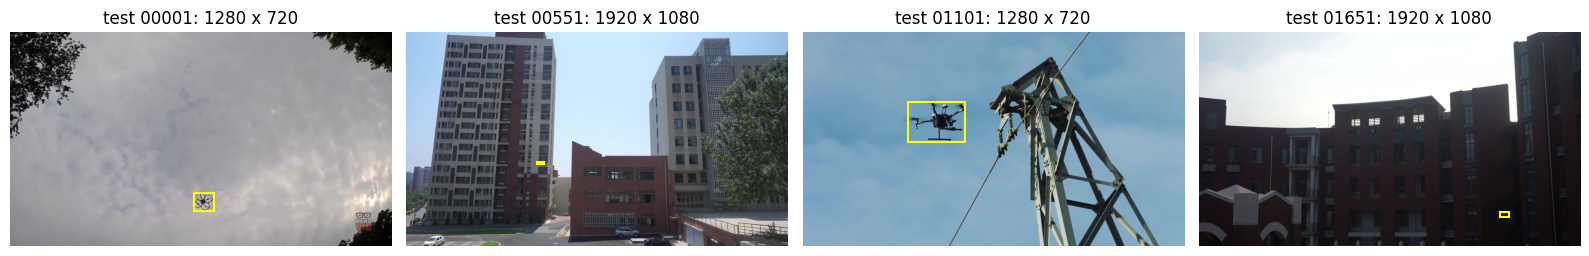

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, row in zip(axes, DETECTION["test"].select(range(0, 2200, 550))):
    ax.imshow(Image.open(io.BytesIO(row["image"]["bytes"])))
    for x1, y1, x2, y2 in row["objects"]["bbox"]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="yellow", lw=1.5))
    ax.set_title(f"test {row['image_id']}: {row['width']} x {row['height']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fine-tuning the detector

You start from a detector pretrained on COCO, whose 80 classes do not include drones, and fine-tune it for the single `UAV` class. The pretrained backbone already encodes edges, textures and object parts, so a few thousand labeled images are enough to adapt the head and the upper layers. Use the nano-sized model of the YOLO11 family (`yolo11n.pt`, about 2.6 million parameters). It trains quickly and runs on every frame of the tracking videos in minutes.

Two settings matter for small targets. The input size sets how many pixels a drone covers after resizing, and the validation split decides which epoch's weights you keep. The training loop keeps the weights with the best validation score in `RUNS/detector/weights/best.pt`.

In [9]:
from ultralytics import YOLO

# TODO: fine-tune the detector. The stub below trains for only 3 epochs so that every later
#   cell runs quickly; its detector is the baseline you must beat. Replace it with your own
#   training run. Keep the output location: later cells load RUNS / "detector" / "weights" / "best.pt".
t0 = time.time()
model = YOLO("yolo11n.pt")
model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=16, workers=2,
            amp=AMP, seed=0, device=DEVICE, project=str(RUNS.resolve()), name="detector",
            exist_ok=True, plots=False, verbose=False)
print(f"training took {(time.time() - t0) / 60:.1f} min")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dut-data/dut.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, 

## Detection accuracy on the test split

Average precision at an IoU threshold of 0.5 (mAP@0.5) counts a detection as correct when its box overlaps a labeled drone by at least half of their union, ranks all detections by confidence, and integrates precision over recall. With one class, the mean over classes is just that class's average precision. The stricter mAP@0.5:0.95 averages the same quantity over IoU thresholds from 0.5 to 0.95. Evaluating at a larger input size than the training size often helps small objects, because the drone covers more pixels.

In [10]:
detector = YOLO(RUNS / "detector" / "weights" / "best.pt")
det_results = {}
for size in (IMGSZ, 1280):
    metrics = detector.val(data=str(DATA_YAML), split="test", imgsz=size, batch=16, device=DEVICE,
                           plots=False, verbose=False, project=str(RUNS.resolve()), name=f"test_{size}",
                           exist_ok=True)
    det_results[size] = (metrics.box.map50, metrics.box.map)
    print(f"test split, input {size}: mAP@0.5 = {metrics.box.map50:.3f}, mAP@0.5:0.95 = {metrics.box.map:.3f}")

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2914.4±776.2 MB/s, size: 231.5 KB)
val: Scanning /content/dut-data/yolo/labels/test... 2200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2200/2200 2.0Kit/s 1.1s
val: New cache created: /content/dut-data/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 7.3it/s 18.9s
                   all       2200       2245      0.924       0.82      0.885      0.559
Speed: 0.9ms preprocess, 2.5ms inference, 0.0ms loss, 1.9ms postprocess per image
test split, input 640: mAP@0.5 = 0.885, mAP@0.5:0.95 = 0.559
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image acces

## The tracking data

The tracking part of the benchmark has 20 videos, `video01` to `video20`, with 24,804 frames in total. Sequences run from 83 to 2,635 frames. Every frame comes with a ground-truth box `[x, y, w, h]`: the top-left corner, the width and the height of the drone's box in pixels. When the drone is out of view, the box reads `[-100, -100, -100, -100]`. That happens in 2,586 frames, all in 9 of the videos, and the loader below turns those boxes into `NaN`. The frames are written to disk once, one folder per video, with one ground-truth file per video holding one line per frame.

In [11]:
TRACK_ROOT = DATA / "track"
if not (TRACK_ROOT / "Anti-UAV-Tracking-V0GT").exists():
    tracking = load_dataset("aegean-ai/dut-anti-uav", "tracking", split="test")
    tracking = tracking.cast_column("image", ImageFeature(decode=False))  # keep raw JPEG bytes
    boxes = {}
    for row in tracking:  # rows are sorted by video, then frame
        frame_dir = TRACK_ROOT / "Anti-UAV-Tracking-V0" / row["video_id"]
        frame_dir.mkdir(parents=True, exist_ok=True)
        (frame_dir / f"{row['frame_index']:05d}.jpg").write_bytes(row["image"]["bytes"])
        boxes.setdefault(row["video_id"], []).append(row["bbox"])
    gt_dir = TRACK_ROOT / "Anti-UAV-Tracking-V0GT"
    gt_dir.mkdir()  # written last, so its presence marks a finished export
    for video_id, rows in boxes.items():
        np.savetxt(gt_dir / f"{video_id}_gt.txt", np.array(rows), fmt="%d")
SEQUENCES = [f"video{i:02d}" for i in range(1, 21)]

Resolving data files:   0%|          | 0/20 [00:00<?, ?it/s]

tracking-parquet/video01.parquet: reconstructing file:   0%|          |  0.00B /  151MB            

tracking-parquet/video01.parquet: downloading bytes:           |  0.00B            

tracking-parquet/video02.parquet: reconstructing file:   0%|          |  0.00B / 6.99MB            

tracking-parquet/video02.parquet: downloading bytes:           |  0.00B            

tracking-parquet/video03.parquet: reconstructing file:   0%|          |  0.00B / 2.19MB            

... (32 outputs left out)

tracking-parquet/video19.parquet: downloading bytes:           |  0.00B            

tracking-parquet/video20.parquet: reconstructing file:   0%|          |  0.00B /  244MB            

tracking-parquet/video20.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/24804 [00:00<?, ? examples/s]

In [12]:
def load_sequence(track_root, name):
    """Frame paths, ground truth (N x 4, x y w h, NaN where the drone is absent), first box."""
    frames = sorted((Path(track_root) / "Anti-UAV-Tracking-V0" / name).glob("*.jpg"))
    gt = np.loadtxt(Path(track_root) / "Anti-UAV-Tracking-V0GT" / f"{name}_gt.txt", dtype=float)
    gt[(gt[:, 2] <= 0) | (gt[:, 3] <= 0)] = np.nan  # -100 -100 -100 -100 marks an absent target
    assert len(frames) == len(gt), (name, len(frames), len(gt))
    return frames, gt

In [13]:
GT = {name: load_sequence(TRACK_ROOT, name)[1] for name in SEQUENCES}
for name in SEQUENCES:
    gt = GT[name]
    visible = ~np.isnan(gt[:, 0])
    print(f"{name}: {len(gt):5d} frames, drone absent in {(~visible).sum():4d}, "
          f"median box {np.nanmedian(gt[:, 2]):.0f} x {np.nanmedian(gt[:, 3]):.0f} px")

video01:  1050 frames, drone absent in    0, median box 95 x 41 px
video02:    83 frames, drone absent in    0, median box 57 x 20 px
video03:   100 frames, drone absent in    0, median box 34 x 34 px
video04:   341 frames, drone absent in    0, median box 86 x 64 px
video05:   450 frames, drone absent in    0, median box 51 x 37 px
video06:   200 frames, drone absent in    0, median box 92 x 72 px
video07:  2480 frames, drone absent in  653, median box 148 x 57 px
video08:  2305 frames, drone absent in  233, median box 92 x 38 px
video09:  2500 frames, drone absent in  938, median box 115 x 50 px
video10:  2635 frames, drone absent in  328, median box 115 x 45 px
video11:  1000 frames, drone absent in    2, median box 158 x 84 px
video12:  1485 frames, drone absent in  147, median box 60 x 36 px
video13:  1915 frames, drone absent in    1, median box 53 x 30 px
video14:   590 frames, drone absent in    0, median box 71 x 41 px
video15:  1350 frames, drone absent in  245, median box 60

## Scoring a tracker

The one-pass evaluation starts the tracker from the ground-truth box in the first frame and lets it run to the end of the sequence without any reset. Two numbers summarize the result.

The success curve plots, for each overlap threshold $\tau$ between 0 and 1, the fraction of frames whose predicted box $B_t$ overlaps the ground truth $G_t$ by more than $\tau$:

$$
\mathrm{IoU}_t = \frac{|B_t \cap G_t|}{|B_t \cup G_t|}, \qquad S(\tau) = \frac{1}{T}\sum_{t=1}^{T} \mathbb{1}\left[\mathrm{IoU}_t > \tau\right].
$$

Its area under the curve (AUC), computed as the mean of $S(\tau)$ over 21 evenly spaced thresholds, is the headline score. The precision curve does the same with the distance between box centers and reports the fraction of frames whose center error is at most 20 pixels.

Frames in which the drone is absent have no ground-truth box, so they are left out of both curves. A frame in which the method reports no box scores an IoU of 0 and an infinite center error. Both curves are computed per sequence and then averaged over the 20 sequences, so a short sequence counts as much as a long one. A separate number, the absent-box rate, measures how often a method still reports a box when the drone is out of view.

In [14]:
def iou_xywh(a, b):
    """IoU of matching rows of two N x 4 arrays of x y w h boxes. NaN rows give IoU 0."""
    ax2, ay2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx2, by2 = b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2, bx2) - np.maximum(a[:, 0], b[:, 0]), 0, None)
    ih = np.clip(np.minimum(ay2, by2) - np.maximum(a[:, 1], b[:, 1]), 0, None)
    inter = iw * ih
    union = a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter
    iou = inter / np.where(union > 0, union, 1)
    return np.nan_to_num(iou, nan=0.0)


def center_error(a, b):
    """Euclidean distance between box centers in pixels. NaN predictions give infinity."""
    ca = a[:, :2] + a[:, 2:] / 2
    cb = b[:, :2] + b[:, 2:] / 2
    err = np.linalg.norm(ca - cb, axis=1)
    return np.where(np.isnan(err), np.inf, err)


IOU_THRESHOLDS = np.linspace(0, 1, 21)
PIXEL_THRESHOLDS = np.arange(0, 51)


def evaluate_sequence(pred, gt):
    """One-pass evaluation of one sequence on the frames where the drone is visible.

    pred and gt are N x 4 arrays of x y w h boxes. A NaN row in pred means the method
    reported no box in that frame and scores IoU 0 and infinite center error.
    Returns the success curve over IOU_THRESHOLDS and the precision curve over
    PIXEL_THRESHOLDS.
    """
    visible = ~np.isnan(gt[:, 0])
    iou = iou_xywh(pred[visible], gt[visible])
    err = center_error(pred[visible], gt[visible])
    success = np.array([(iou > t).mean() for t in IOU_THRESHOLDS])
    precision = np.array([(err <= t).mean() for t in PIXEL_THRESHOLDS])
    return success, precision


def evaluate_all(preds, gts):
    """Average per-sequence curves. Returns success AUC, precision at 20 px, and the curves."""
    curves = [evaluate_sequence(preds[k], gts[k]) for k in gts]
    success = np.mean([c[0] for c in curves], axis=0)
    precision = np.mean([c[1] for c in curves], axis=0)
    return {"auc": float(success.mean()), "p20": float(precision[20]),
            "success": success, "precision": precision}


def absent_box_rate(pred, gt):
    """Fraction of frames with no drone in which the method still reports a box."""
    absent = np.isnan(gt[:, 0])
    if not absent.any():
        return np.nan
    return float((~np.isnan(pred[absent, 0])).mean())

## Detections on every frame

The tracker consumes the detector's output one frame at a time. Running the detector is the slow step, so it runs once over all 24,804 frames and the boxes are saved: up to 10 boxes per frame with confidence of at least 0.01, each stored as `x1 y1 x2 y2 confidence`. The low floor keeps weak detections so that the tracker, not the detector, decides which ones to trust. The file is named after the detector's weights, so a retrained detector never reuses old boxes.

In [15]:
import hashlib

WEIGHTS = RUNS / "detector" / "weights" / "best.pt"
CACHE = DATA / f"detections_{TRACK_IMGSZ}_{hashlib.md5(WEIGHTS.read_bytes()).hexdigest()[:8]}.pkl"
if CACHE.exists():
    DETS = pickle.loads(CACHE.read_bytes())
else:
    DETS, t0 = {}, time.time()
    for name in SEQUENCES:
        frames, _ = load_sequence(TRACK_ROOT, name)
        per_frame = []
        for i in range(0, len(frames), 16):
            for r in detector.predict([str(f) for f in frames[i:i + 16]], imgsz=TRACK_IMGSZ, conf=0.01,
                                      max_det=10, half=AMP, device=DEVICE, verbose=False):
                per_frame.append(np.hstack([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]]))
        DETS[name] = per_frame
        print(f"{name}: {len(frames)} frames, {time.time() - t0:.0f} s so far")
    CACHE.write_bytes(pickle.dumps(DETS))

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

## The detector on its own

The simplest tracker reports, in every frame, the detector's most confident box, and reports nothing when no box clears a confidence threshold. It has no memory. A missed detection becomes a lost frame, and a confident false positive anywhere in the image becomes the track. The first frame is set to the ground truth, exactly as the Kalman tracker will be, so the two methods start from the same place.

In [16]:
def best_box_per_frame(dets, min_conf):
    """Highest-confidence detection in each frame, as x y w h; NaN when none passes min_conf.

    dets is a list with one (K x 5) array per frame: x1 y1 x2 y2 conf.
    """
    out = np.full((len(dets), 4), np.nan)
    for i, d in enumerate(dets):
        d = d[d[:, 4] >= min_conf]
        if len(d):
            x1, y1, x2, y2, _ = d[np.argmax(d[:, 4])]
            out[i] = [x1, y1, x2 - x1, y2 - y1]
    return out

In [17]:
def detector_only(min_conf):
    preds = {}
    for name in SEQUENCES:
        p = best_box_per_frame(DETS[name], min_conf)
        p[0] = GT[name][0]
        preds[name] = p
    return preds


def summary(preds):
    r = evaluate_all(preds, GT)
    r["absent"] = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in SEQUENCES])
    return r


for th in (0.01, 0.05, 0.1, 0.25, 0.5):
    r = summary(detector_only(th))
    print(f"min confidence {th:4.2f}: success AUC {r['auc']:.3f}, precision@20px {r['p20']:.3f}, "
          f"absent-box rate {r['absent']:.2f}")

min confidence 0.01: success AUC 0.629, precision@20px 0.838, absent-box rate 0.99
min confidence 0.05: success AUC 0.627, precision@20px 0.835, absent-box rate 0.76
min confidence 0.10: success AUC 0.624, precision@20px 0.831, absent-box rate 0.58
min confidence 0.25: success AUC 0.614, precision@20px 0.814, absent-box rate 0.44
min confidence 0.50: success AUC 0.582, precision@20px 0.762, absent-box rate 0.17


## A Kalman filter for one drone

The filter tracks the box center, the velocity of the center, and the box size, so its state is

$$
\mathbf{x} = \begin{bmatrix} c_x & c_y & v_x & v_y & w & h \end{bmatrix}^\top .
$$

A detection gives the measurement $\mathbf{z} = [c_x, c_y, w, h]^\top$. It observes the center and the size but not the velocity. The center moves with constant velocity, one step per frame, and the width and height follow a random walk. From this description you derive the transition matrix $F$, the measurement matrix $H$, the process noise $Q$ and the measurement noise $R$.

Not every detection comes from the drone. Before each update the filter compares the detections with its prediction and rejects those that lie too far from it. Measure that distance with the squared Mahalanobis distance of the innovation, and set the threshold from the distribution that distance follows when the detection is correct. When no detection passes, the filter skips the update and coasts on its prediction. You decide how long a track may coast before it is declared lost, and how a new track starts after that.

In [18]:
from filterpy.kalman import KalmanFilter

In [19]:
def xyxy_to_z(box):
    """[x1, y1, x2, y2] to the measurement [cx, cy, w, h]."""
    x1, y1, x2, y2 = box[:4]
    return np.array([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1])


def z_to_xywh(z):
    """[cx, cy, w, h] to the evaluation format [x, y, w, h] (top-left corner)."""
    cx, cy, w, h = z
    return np.array([cx - w / 2, cy - h / 2, w, h])

In [30]:
class DroneTracker:
    """Kalman tracker for a single drone.

    State x = [cx, cy, vx, vy, w, h]; measurement z = [cx, cy, w, h]; one step = one frame.
    accel_std and meas_std are the process and measurement noise settings swept later on.
    """

    def __init__(self, accel_std=1.0, meas_std=1.0,
                 size_std=None,
                 max_missed=20,
                 gate_threshold=18.47,
                 gate_floor=0.5,
                 vel_decay=0.95,
                 near_conf=0.05,
                 reacquire_radius=2.0,
                 reacquire_growth=0.25,
                 reacquire_max=10.0,
                 confident_conf=0.4):
        self.accel_std = accel_std
        self.meas_std = meas_std
        self.size_std = accel_std if size_std is None else size_std
        self.max_missed = max_missed
        self.gate_threshold = gate_threshold
        self.gate_floor = gate_floor
        self.vel_decay = vel_decay
        self.near_conf = near_conf
        self.reacquire_radius = reacquire_radius
        self.reacquire_growth = reacquire_growth
        self.reacquire_max = reacquire_max
        self.confident_conf = confident_conf
        self.kf = None
        self.missed = 0
        self.lost = False
        self.lost_frames = 0
        self.last_z = None  # [cx, cy, w, h] where the track was lost

    def start(self, z):
        z = np.asarray(z, dtype=float)
        kf = KalmanFilter(dim_x=6, dim_z=4)
        kf.F = np.array([
            [1, 0, 1, 0, 0, 0],
            [0, 1, 0, 1, 0, 0],
            [0, 0, 1, 0, 0, 0],
            [0, 0, 0, 1, 0, 0],
            [0, 0, 0, 0, 1, 0],
            [0, 0, 0, 0, 0, 1],
        ], dtype=float)
        kf.H = np.array([
            [1, 0, 0, 0, 0, 0],
            [0, 1, 0, 0, 0, 0],
            [0, 0, 0, 0, 1, 0],
            [0, 0, 0, 0, 0, 1],
        ], dtype=float)
        kf.R = np.eye(4) * self.meas_std**2

        a2 = self.accel_std**2
        Q = np.zeros((6, 6))
        for p, v in ((0, 2), (1, 3)):
            Q[p, p] = a2 / 4
            Q[p, v] = Q[v, p] = a2 / 2
            Q[v, v] = a2
        Q[4, 4] = Q[5, 5] = self.size_std**2
        kf.Q = Q

        kf.x = np.array([[z[0]], [z[1]], [0.0], [0.0], [z[2]], [z[3]]])
        m2 = self.meas_std**2
        v2 = (0.5 * max(z[2], z[3], 1.0))**2
        kf.P = np.diag([m2, m2, v2, v2, m2, m2])

        self.kf = kf
        self.missed = 0
        self.lost = False
        self.lost_frames = 0

    def _estimate(self):
        return z_to_xywh(self.kf.x[[0, 1, 4, 5], 0])

    def _gate(self, Z):
        kf = self.kf
        scale = max(kf.x[4, 0], kf.x[5, 0], 1.0)
        S = kf.H @ kf.P @ kf.H.T + kf.R + np.eye(4) * (self.gate_floor * scale) ** 2
        y = Z - (kf.H @ kf.x).T
        return np.einsum('ij,jk,ik->i', y, np.linalg.inv(S), y)

    def _reacquire(self, dets, Z):
        if len(dets) == 0:
            return None
        conf = dets[:, 4]
        if self.last_z is not None:
            scale = max(self.last_z[2], self.last_z[3], 1.0)
            radius = scale * min(self.reacquire_radius
                                 + self.reacquire_growth * self.lost_frames,
                                 self.reacquire_max)
            dist = np.hypot(Z[:, 0] - self.last_z[0], Z[:, 1] - self.last_z[1])
            near = (dist <= radius) & (conf >= self.near_conf)
            if near.any():
                return int(np.argmax(np.where(near, conf, -np.inf)))
        far = conf >= self.confident_conf
        if far.any():
            return int(np.argmax(np.where(far, conf, -np.inf)))
        return None

    def step(self, dets):
        dets = np.asarray(dets, dtype=float).reshape(-1, 5)
        Z = np.array([xyxy_to_z(d) for d in dets]).reshape(-1, 4)
        nan = np.full(4, np.nan)

        if self.kf is None:
            if len(dets) == 0:
                return nan
            idx = int(np.argmax(dets[:, 4]))
            self.start(Z[idx])
            return z_to_xywh(Z[idx])

        if self.lost:
            self.lost_frames += 1
            idx = self._reacquire(dets, Z)
            if idx is None:
                return nan
            self.start(Z[idx])
            return z_to_xywh(Z[idx])

        self.kf.predict()

        chosen = None
        if len(Z) > 0:
            inside = self._gate(Z) <= self.gate_threshold
            if inside.any():
                chosen = int(np.argmax(np.where(inside, dets[:, 4], -np.inf)))
            top = int(np.argmax(dets[:, 4]))
            if (top != chosen and dets[top, 4] >= self.confident_conf
                    and (chosen is None or dets[top, 4] >= 2 * dets[chosen, 4])):
                self.start(Z[top])
                return z_to_xywh(Z[top])

        if chosen is not None:
            self.kf.update(Z[chosen].reshape(4, 1))
            self.missed = 0
            return self._estimate()

        self.missed += 1
        self.kf.x[2:4] *= self.vel_decay

        if self.missed > self.max_missed:
            self.last_z = self.kf.x[[0, 1, 4, 5], 0].copy()
            self.lost = True
            self.lost_frames = 0
            idx = self._reacquire(dets, Z)
            if idx is not None:
                self.start(Z[idx])
                return z_to_xywh(Z[idx])
            return nan

        return self._estimate()

In [31]:
def run_tracker(dets, first_box, **params):
    """Track one sequence. first_box is the ground truth x y w h of frame 1 (one-pass protocol)."""
    tracker = DroneTracker(**params)
    x, y, w, h = first_box
    tracker.start(np.array([x + w / 2, y + h / 2, w, h]))
    out = [np.array(first_box, dtype=float)]
    for d in dets[1:]:
        out.append(tracker.step(d))
    return np.array(out)

## Tracking all 20 sequences

Choose the settings of `DroneTracker` on the odd-numbered sequences only, and use the even-numbered ones to check that you did not fit them to the videos you score on. The table reports the detector alone, at the confidence threshold that scores best on the odd sequences, next to the Kalman tracker. Until you implement the filter, the tracker's stub reports the detector's most confident box, so its row matches the detector alone. Once the filter runs, compare the two rows column by column and explain what you see.

In [35]:
ODD = [k for k in SEQUENCES if int(k[-2:]) % 2 == 1]
EVEN = [k for k in SEQUENCES if int(k[-2:]) % 2 == 0]


def score(preds, keys):
    r = evaluate_all({k: preds[k] for k in keys}, {k: GT[k] for k in keys})
    absent = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in keys])
    return r["auc"], r["p20"], absent


best_th = max((0.01, 0.05, 0.1, 0.25, 0.5), key=lambda th: score(detector_only(th), ODD)[0])
DET_PREDS = detector_only(best_th)
t0 = time.time()
KF_PREDS = {name: run_tracker(DETS[name], GT[name][0]) for name in SEQUENCES}
print(f"Kalman tracking of {sum(len(g) for g in GT.values())} frames took {time.time() - t0:.1f} s")
print(f"{'method':32s} {'subset':6s} {'AUC':>6s} {'P@20':>6s} {'absent':>7s}")
for label, preds in ((f"detector alone (conf >= {best_th})", DET_PREDS), ("detector + Kalman filter", KF_PREDS)):
    for subset, keys in (("odd", ODD), ("even", EVEN), ("all", SEQUENCES)):
        auc, p20, absent = score(preds, keys)
        print(f"{label:32s} {subset:6s} {auc:6.3f} {p20:6.3f} {absent:7.2f}")

Kalman tracking of 24804 frames took 4.0 s
method                           subset    AUC   P@20  absent
detector alone (conf >= 0.01)    odd     0.625  0.816    0.99
detector alone (conf >= 0.01)    even    0.633  0.861    0.98
detector alone (conf >= 0.01)    all     0.629  0.838    0.99
detector + Kalman filter         odd     0.633  0.829    0.83
detector + Kalman filter         even    0.651  0.894    0.66
detector + Kalman filter         all     0.642  0.861    0.75


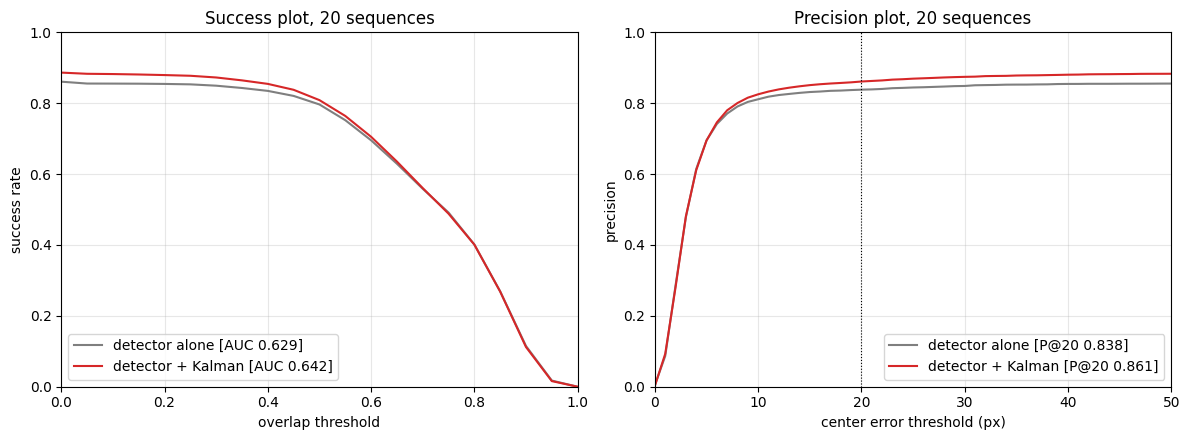

In [37]:
det_all, kf_all = evaluate_all(DET_PREDS, GT), evaluate_all(KF_PREDS, GT)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for r, label, color in ((det_all, "detector alone", "tab:gray"), (kf_all, "detector + Kalman", "tab:red")):
    a1.plot(IOU_THRESHOLDS, r["success"], color=color, label=f"{label} [AUC {r['auc']:.3f}]")
    a2.plot(PIXEL_THRESHOLDS, r["precision"], color=color, label=f"{label} [P@20 {r['p20']:.3f}]")
a1.set(xlabel="overlap threshold", ylabel="success rate", title="Success plot, 20 sequences", xlim=(0, 1), ylim=(0, 1))
a2.set(xlabel="center error threshold (px)", ylabel="precision", title="Precision plot, 20 sequences", xlim=(0, 50), ylim=(0, 1))
a2.axvline(20, color="k", lw=0.8, ls=":")
for a in (a1, a2):
    a.grid(alpha=0.3)
    a.legend(loc="lower left" if a is a1 else "lower right")
plt.tight_layout()
plt.show()

In [38]:
rows = []
for name in SEQUENCES:
    d_auc, _, _ = score(DET_PREDS, [name])
    k_auc, _, _ = score(KF_PREDS, [name])
    rows.append((name, d_auc, k_auc))
print(f"{'sequence':9s} {'frames':>6s} {'absent':>6s} {'det AUC':>8s} {'KF AUC':>7s} {'change':>7s}")
for name, d_auc, k_auc in rows:
    gt = GT[name]
    print(f"{name:9s} {len(gt):6d} {int(np.isnan(gt[:, 0]).sum()):6d} {d_auc:8.3f} {k_auc:7.3f} {k_auc - d_auc:+7.3f}")

sequence  frames absent  det AUC  KF AUC  change
video01     1050      0    0.677   0.689  +0.012
video02       83      0    0.656   0.663  +0.007
video03      100      0    0.834   0.840  +0.006
video04      341      0    0.683   0.669  -0.014
video05      450      0    0.779   0.793  +0.014
video06      200      0    0.854   0.861  +0.007
video07     2480    653    0.792   0.774  -0.018
video08     2305    233    0.829   0.820  -0.009
video09     2500    938    0.879   0.882  +0.003
video10     2635    328    0.762   0.767  +0.005
video11     1000      2    0.769   0.770  +0.001
video12     1485    147    0.468   0.502  +0.034
video13     1915      1    0.066   0.070  +0.004
video14      590      0    0.580   0.594  +0.014
video15     1350    245    0.446   0.414  -0.032
video16     1285      0    0.211   0.300  +0.090
video17      780      0    0.485   0.570  +0.085
video18     1320     39    0.680   0.685  +0.005
video19     1300      0    0.518   0.529  +0.011
video20     1635    

/tmp/ipykernel_2573/1150791356.py:7: RuntimeWarning: Mean of empty slice
  absent = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in keys])


## The track drawn on the video

The output video for one sequence shows the ground-truth box in green, the Kalman estimate in red, and the estimated center's path as a red polyline. The path breaks where the track was lost. Frames with no drone in view have no green box.

In [48]:
VIDEO_NAME = "video15"  # change this to look at another sequence


def render(name, preds, out_path, scale=0.5, fps=25):
    frames, gt = load_sequence(TRACK_ROOT, name)
    writer, path = None, []
    for i, frame_path in enumerate(frames):
        image = cv2.imread(str(frame_path))
        image = cv2.resize(image, None, fx=scale, fy=scale)
        if writer is None:
            h, w = image.shape[:2]
            writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
        g, p = gt[i] * scale, preds[i] * scale
        if not np.isnan(g[0]):
            cv2.rectangle(image, (int(g[0]), int(g[1])), (int(g[0] + g[2]), int(g[1] + g[3])), (0, 200, 0), 1)
        if np.isnan(p[0]):
            path.append(None)
        else:
            cv2.rectangle(image, (int(p[0]), int(p[1])), (int(p[0] + p[2]), int(p[1] + p[3])), (0, 0, 255), 2)
            path.append((int(p[0] + p[2] / 2), int(p[1] + p[3] / 2)))
        for a, b in zip(path[:-1], path[1:]):
            if a is not None and b is not None:
                cv2.line(image, a, b, (0, 0, 255), 1)
        cv2.putText(image, f"{name} frame {i + 1}", (10, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        writer.write(image)
    writer.release()
    return out_path


video_path = render(VIDEO_NAME, KF_PREDS[VIDEO_NAME], Path(f"{VIDEO_NAME}_kalman.mp4"))
print("wrote", video_path)

wrote video15_kalman.mp4


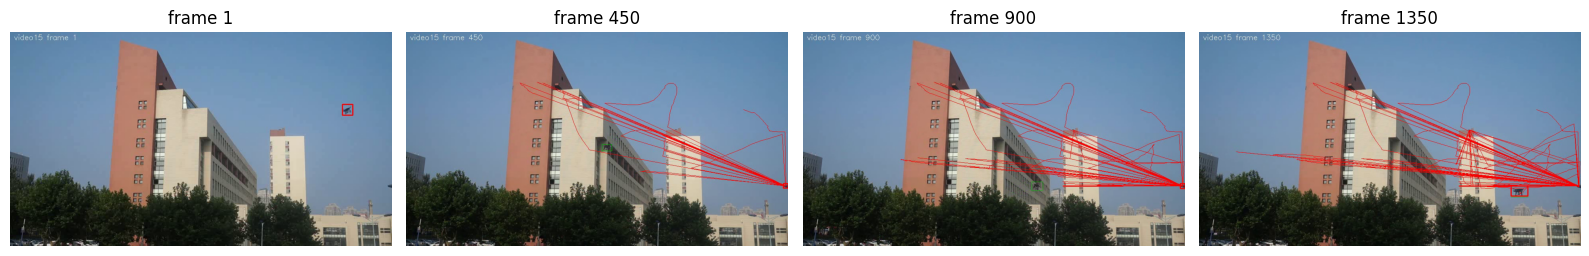

In [49]:
capture = cv2.VideoCapture(str(video_path))
count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axes = plt.subplots(1, 4, figsize=(16, 2.8))
for ax, index in zip(axes, np.linspace(0, count - 1, 4).astype(int)):
    capture.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, frame = capture.read()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {index + 1}")
    ax.axis("off")
capture.release()
plt.tight_layout()
plt.show()

## Losing and reacquiring the drone

On a hard sequence, much of a tracker's score depends on how it finds the drone again after losing it. video13 is the hardest case in the benchmark. The drone is small and often hard to see, and the detector finds it in only part of the frames, many of them with low confidence. Long stretches pass with no detection on the drone at all.

A tracker that gives up after a run of missed frames, and then waits for a confident detection anywhere in the image, can stay silent through long stretches in which the detector does see the drone. On such a sequence it can score below the detector alone, even though it has the same detections and more information about where the drone was.

Your tracker has to handle this case. Decide when the track counts as lost, what the filter does while it is lost, and which detections may restart it. Change `DroneTracker` above, choose any new settings on the odd-numbered sequences as before, and rerun the cells from the tracking section down. Your final tracker must meet two conditions:

- On video13, its AUC is at least that of the detector alone.
- Over all 20 sequences, its absent-box rate stays below that of the detector alone.

The check below reports both. The plot after it shows, frame by frame, the overlap of each method's box with the ground truth. A red band marks frames in which the method reports no box while the drone is in view, and a gray band marks frames with no drone in view.

In [41]:
d13, k13 = score(DET_PREDS, ["video13"]), score(KF_PREDS, ["video13"])
d_all, k_all = score(DET_PREDS, SEQUENCES), score(KF_PREDS, SEQUENCES)
print(f"video13 AUC: detector alone {d13[0]:.3f}, your tracker {k13[0]:.3f}")
print(f"absent-box rate on all 20 sequences: detector alone {d_all[2]:.2f}, your tracker {k_all[2]:.2f}")
met = k13[0] >= d13[0] and k_all[2] < d_all[2]
print("both conditions met" if met else "not met yet")

video13 AUC: detector alone 0.066, your tracker 0.070
absent-box rate on all 20 sequences: detector alone 0.99, your tracker 0.75
both conditions met


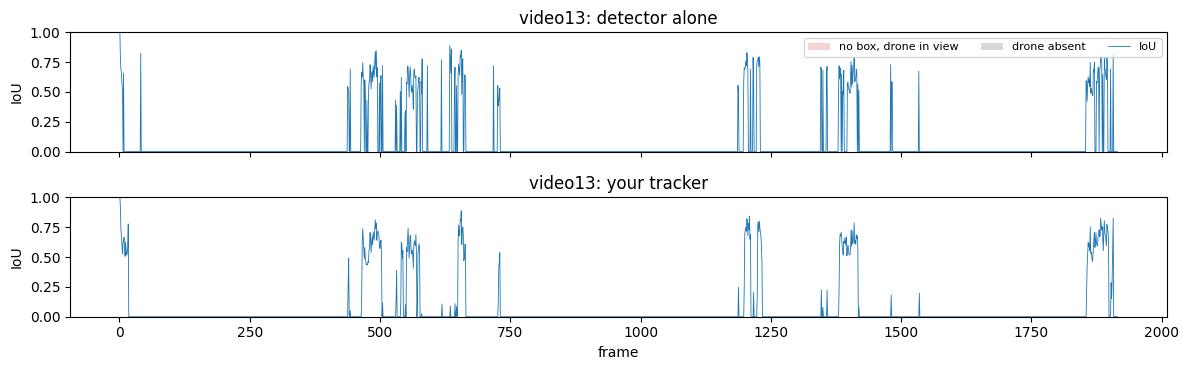

In [42]:
def plot_timeline(name, preds_by_label):
    """Per-frame IoU with the ground truth for each method on one sequence."""
    gt = GT[name]
    t = np.arange(1, len(gt) + 1)
    fig, axes = plt.subplots(len(preds_by_label), 1, figsize=(12, 1.9 * len(preds_by_label)), sharex=True,
                             squeeze=False)
    for ax, (label, pred) in zip(axes[:, 0], preds_by_label.items()):
        absent = np.isnan(gt[:, 0])
        nobox = np.isnan(pred[:, 0]) & ~absent
        ax.fill_between(t, 0, 1, where=nobox, color="tab:red", alpha=0.2, step="mid", lw=0,
                        label="no box, drone in view")
        ax.fill_between(t, 0, 1, where=absent, color="0.5", alpha=0.3, step="mid", lw=0, label="drone absent")
        ax.plot(t, iou_xywh(pred, gt), color="tab:blue", lw=0.6, label="IoU")
        ax.set(ylim=(0, 1), ylabel="IoU", title=f"{name}: {label}")
    axes[-1, 0].set_xlabel("frame")
    axes[0, 0].legend(loc="upper right", fontsize=8, ncol=3)
    plt.tight_layout()
    plt.show()


plot_timeline("video13", {"detector alone": DET_PREDS["video13"], "your tracker": KF_PREDS["video13"]})

## Noise sensitivity

The ratio of process noise to measurement noise sets how much the filter trusts its motion model over the detector. Sweep `accel_std` and `meas_std` over at least three values each, keeping the other settings at their defaults, and score each setting on all 20 sequences. Use the result in your answer to question 2.

In [47]:
# TODO: extend both lists to at least three values each.
ACCEL_GRID = [0.5,1.0,1.5,2.0]
MEAS_GRID = [0.5,1.0,1.5,2.0]
print(f"{'accel_std':>9s} {'meas_std':>8s} {'AUC':>6s} {'P@20':>6s}")
SWEEP = {}
for accel_std in ACCEL_GRID:
    for meas_std in MEAS_GRID:
        preds = {n: run_tracker(DETS[n], GT[n][0], accel_std=accel_std, meas_std=meas_std) for n in SEQUENCES}
        auc, p20, _ = score(preds, SEQUENCES)
        SWEEP[(accel_std, meas_std)] = (auc, p20)
        print(f"{accel_std:9.2f} {meas_std:8.2f} {auc:6.3f} {p20:6.3f}")

accel_std meas_std    AUC   P@20
     0.50     0.50  0.642  0.863
     0.50     1.00  0.642  0.862
     0.50     1.50  0.639  0.860
     0.50     2.00  0.636  0.857
     1.00     0.50  0.642  0.861
     1.00     1.00  0.642  0.861
     1.00     1.50  0.642  0.863
     1.00     2.00  0.642  0.862
     1.50     0.50  0.641  0.860
     1.50     1.00  0.641  0.859
     1.50     1.50  0.641  0.859
     1.50     2.00  0.642  0.861
     2.00     0.50  0.638  0.855
     2.00     1.00  0.640  0.858
     2.00     1.50  0.640  0.858
     2.00     2.00  0.640  0.859


## Questions

Answer each question in the cell below it, in a few sentences, and support your answer with numbers from your own run.

**Question 1. State design.** The state models the center with constant velocity and the size with a random walk. Why is it reasonable to leave the size without a velocity term on these videos? Name one situation in the benchmark where a constant-velocity model on the center is wrong, and say what the filter does in that situation.



```
# This is formatted as code
```
It is reasonable to leave the size without a velocity term on these videos because the drone stays the same physical size throughout the videos. The state is x = [cx, cy, vx, vy, w, h], so it assumes that the drone’s center will move with a constant velocity, the bounding box size will stay relatively the same, and the bounding box changes will only be caused by small detection errors or perspective of the camera to the drone. This is why the filter models the size without continuously growing or shrinking. One situation where the constant-velocity model is incorrect is in video12, when the drone abruptly hovers near the building. Then the tracker incorrectly associated a nearby detection with another object, such as the telephone tower. In this situation, the filter continues predicting the drone's position based on its previous estimated velocity. Since there is no new detection as the drone was relatively stagnant, the tracker will continue to follow the predicted trajectory rather than the drone's actual movement. This can cause the predicted bounding box to drift away from its true position.

**Question 2. Noise choices.** Use your sweep. What happens to the scores when `accel_std` is much smaller than `meas_std`, and when it is much larger? Explain each trend with the Kalman gain: which source does the filter trust in each case, and what kind of error does that produce on a fast-moving drone and on a jittery detector?

When the filter performs poorly when accel_std is much smaller than mean_std, then the filter assumes the drone’s motions are predictable and the detector movements are not reliable. In the sweep, while keeping accel_std = 0.1 and the meas_std goes from 0.1 to 4.0, the AUC decreases from 0.642 to 0.524, and P@20 decreases from 0.862 to 0.779. This shows that if there are sudden movements, the tracker will fail to correct its movements since the Kalman gain becomes smaller. Therefore, it will lag behind the drone. When the filter performs poorly when mean_std is much smaller than the accel_std, the filter assumes that the drone motions are less predictable and the detector movements are more predictable. In the sweep, the accel_std is at 4.0 and the meas_std is at 0.1, the AUC decreased to 0.634 and P@20 decreased to 0.848 compared to when accel_std is at 0.1 and the mean_std is at 0.1 where the AUC is at 0.642 and the P@20 is at 0.861. This shows that when the Kalman filter trusts the detector measurements more than the detections, it will detect more jitter in the movements because of the less stable position estimations.


**Question 3. Gating and missed detections.** Compare the absent-box rates of the two methods and explain the difference. What do your coasting limit and the gate trade off when the drone leaves the frame or passes behind a tree?

When using the method of the detector alone, there is the absent box rate of 0.99. When using the method of the detector and the Kalman filter, the absent box rate becomes 0.75. The difference between these percentages shows that the Kalman tracker reduced the absent-box rate by 0.24, which shows that the tracker helped to maintain position predictions when the detector failed to identify the drone. The coasting limit determines how many missed frames can occur for the tracker to declare that the detector is lost. A higher coasting limit (max_missed = 20) that has been used allows the tracker to handle longer occlusions to the drone to prevent premature tracking termination, but it can increase the risk of the tracker drifting away from the drone if its actual movements differ from its prediction. The gate controls which detections are accepted by the drone. The tighter gate reduces the chance of incorrectly following another object but it may reject the drone if it moves unexpectedly. The wider gate makes reacquisition of the object easier but it may associate the track with another object instead of the drone. In the DroneTracker, the function reacquisition looks for the drone’s last known position and if there are no nearby detections, it looks for a highly confident detection that has occurred anywhere. Therefore, my tracker uses the wider gate after the drone is declared lost.


**Question 4. Failure cases.** Pick the sequence where the Kalman tracker scores lowest, or where it does worse than the detector alone. Render it with `render`, watch it, and describe what goes wrong and in which frames. Would a better motion model fix it, or does the problem sit in the detector?

Video15 scores the lowest because it has a detector AUC of 0.446 and Kalman AUC of 0.414, which is a highest decrease of 0.032. This indicates that the Kalman filtering doesn’t improve the performance of the tracking and the detection of the object is already challenged. When watching the sequence, the tracking is momentarily lost when the drone passes in front of buildings and it is reacquired when the drone is against the sky, which shows that the changes in the background make it harder for the detector to distinguish the drone from the surroundings. This example is shown in frames 450 and 900. Since the current tracker is able to maintain the predicted position during the detection failures, a better detector is needed for it to handle complex backgrounds. This can be done through training on diverse images and using data augmentation.


**Question 5. Where the numbers come from.** The 424 training and validation images that are frames of the tracking videos were held out of training. Other detection images may still come from the same sites as the tracking videos, filmed at another time. What does that mean for how far you would trust these tracking scores on video from a new site? Would it change the comparison between the detector alone and the detector with the filter, and why?

There are 424 training and validation images that the detector was not directly trained on, but it was trained on images that are from the same sites at different times. This can create data leakage or bias towards the site-specific images because of the lack of generalization. Therefore, the tracking scores might overestimate the performance of the detector on those videos that were recorded on new sites. However, the comparison between the detector and the detector with the Kalman filter is still useful because they are still evaluated on the same videos. However, their performance could change at a new site because the unfamiliar sequences can produce less reliable detections. The Kalman filter will help for the missed detections, but the detector will make worse predictions.

**Question 6. Losing and reacquiring the track.** Describe how your tracker decides that the drone is lost, what the filter does while the track is lost, and which detections can restart it. Report the video13 AUC and the absent-box rate on all 20 sequences with and without your reacquisition rule, and show the video13 plot for both with `plot_timeline`. What does the rule cost on the other sequences?

The tracker considers the drone lost when it can’t find a detection within the Mahalanobis gating threshold for more than 20 missed frames. The Kalman filter continues predicting the drone's position using its estimated velocity. However, the velocity is reduced toward zero to prevent the predicted position from drifting too far from the drone's last known location. The Mahalanobis gate determines whether a new detection is close enough to the predicted position to be accepted. If no detection passes this gate within the 20-frame limit, the tracker enters the lost state and stops outputting bounding-box predictions.Once the tracker is lost, it either accepts a detection with confidence ≥ 0.05 if it falls within an expanding radius of the drone's last known position or it accepts any detection in the frame with confidence ≥ 0.4 anywhere in the video. The tracker initializes a new Kalman filter using the accepted detection's bounding-box coordinates and dimensions to reset the tracking state. Reacquisition improves Video13's Kalman AUC from 0.065 to 0.070, an increase of 0.005. The absent-box count remains unchanged at 1 out of 1,915 frames. Across the other 19 sequences, reacquisition improves Kalman Filter AUC in 16 sequences and decreases it in only 3 sequences. The absent-box count remains unchanged at 2,585 out of 24,889 frames across these 19 sequences. These are the plots for Video13 without the reacquisition and with the reacquisition. Without reacquisition, the tracker's IoU become more skewed and it stops after the 250 frame mark, which indicates less accurate bounding-box localization. With reacquisition,the IOU of the tracker has improved alignment with the detector's IoU pattern.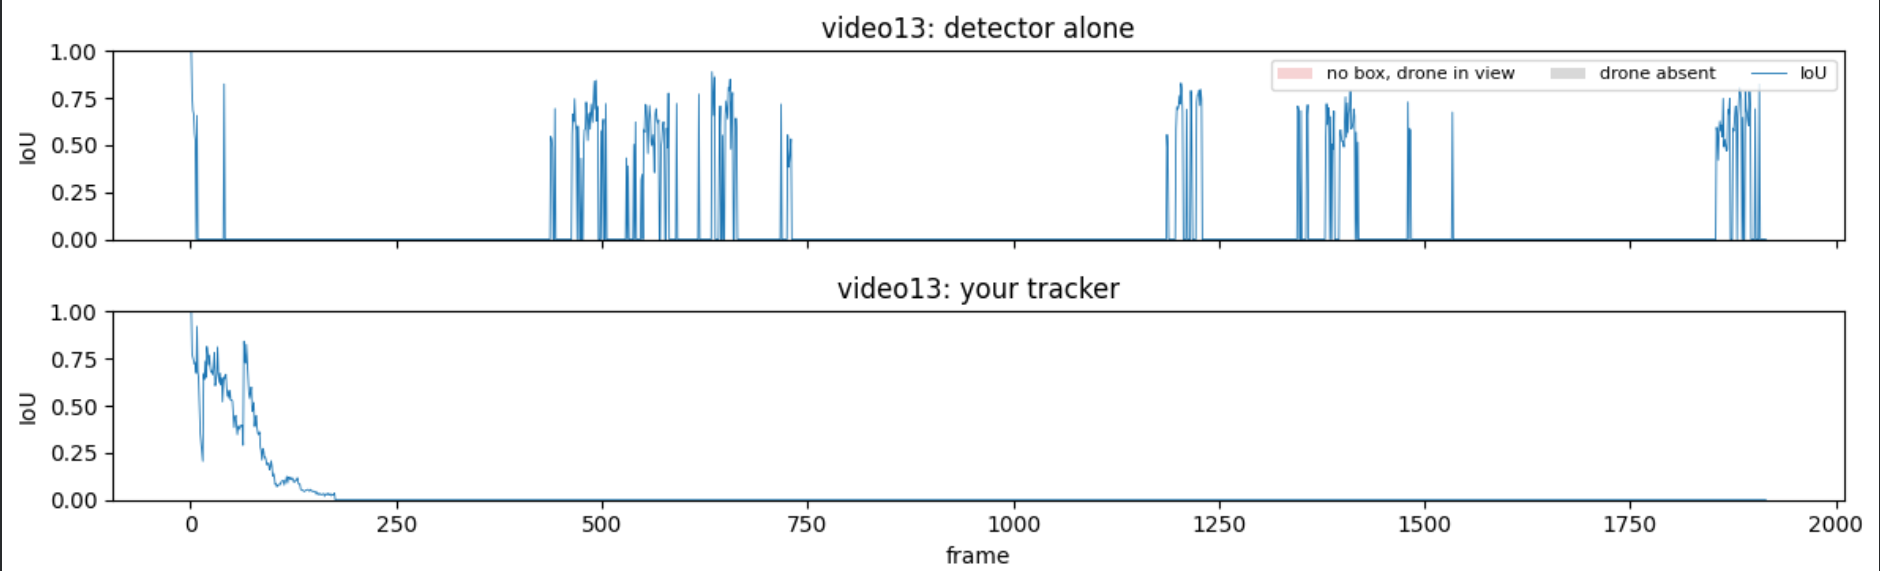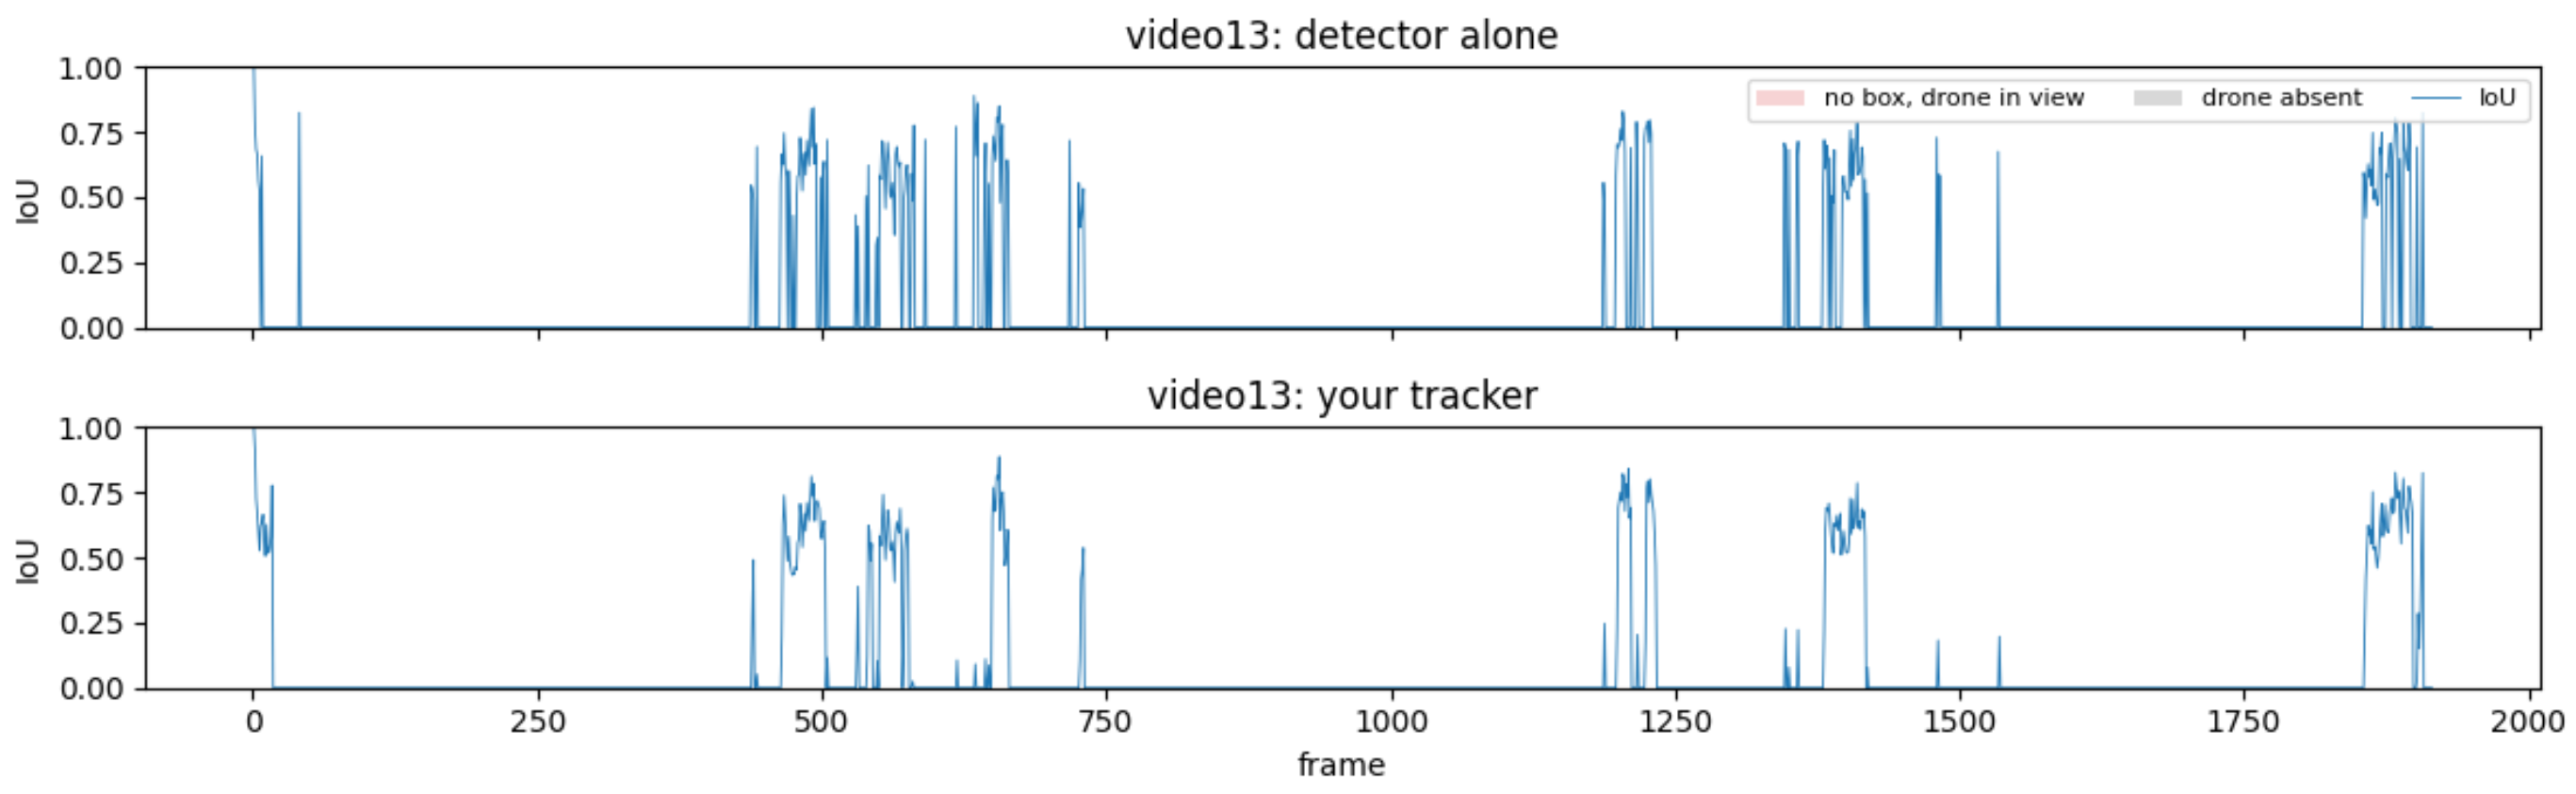